##### Master Degree in Computer Science and Data Science for Economics and Health

# GPT: a decoder that writes

### Prof. Alfio Ferrara

## Introduction

In L1.2 a translation needed two networks working together: an **encoder** that read the source and a **decoder** that wrote the target, connected by the cross-attention. In L1.3 we kept the encoder alone and we obtained BERT, a network that *understands*. Here we do the opposite and keep the **decoder alone**: this is GPT (Radford et al., 2018), and the family of models that today write almost every text produced by a machine.

A decoder-only network has a single input, a text, and a single task, to write the next word. It has no separate source, no memory to read, no cross-attention. The questions of this notebook follow from this fact:

1. **Step 1**: the task. If there is no separate source, how do we ask a decoder to translate? We write the source and the target in the *same* text;
2. **Step 2**: the theory. The three uses of the attention of L1.2 become one, with a single mask. We see where the encoder and the cross-attention went;
3. **Step 3**: the experiment. We compare the decoder-only network with the encoder-decoder of L1.2 on the same translation, we repeat the lesson of the worlds, and we look for the "encoder" inside the network;
4. **Step 4**: why decoders are trained on every word of a text, and what the masked words of BERT cost;
5. **Step 5**: tokenization with BPE, and what happens to a name that the network has never seen;
6. **Step 6**: a vector for the whole text. In BERT it is the vector of `[CLS]`; a decoder has no such position, and we see where to take the vector (which position, which layer);
7. **Step 7**: classification with a decoder: by the likelihood of the text, by turning the label into a word, and by *in-context learning* (a prompt that contains the examples);
8. **Step 8**: how to choose the next word (greedy, temperature, top-k, top-p, beam search);
9. **Step 9**: the key-value cache;
10. **Step 10**: the real GPT-2, in a section that can be run on its own.

The networks that take time to train are saved **outside the repository**, in `models/L1.4/` (the function `trained_network` below): if the file is there the network is loaded, otherwise it is trained and saved. The first run takes about nine minutes, the next ones about one minute. If you change the data, the settings or `nlp/tinylm.py`, delete the folder.

As in the previous notebooks, the toy world has its advantages (we can read everything and train in seconds) and its limits: our networks have tens of thousands of parameters and learn the translation of a small world, while GPT-2 has 124 million parameters and learned from millions of web pages. We say at each step what changes, and we use two seeds: the numbers are an indication, not a measure.

In [1]:
import os
import re
import time
import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from nlp import toyworld, tinylm

warnings.filterwarnings("ignore", category=FutureWarning)

CACHE = "../../models/L1.4"                  # outside the repository: the trained networks, saved only to save time

def trained_network(name, train):
    # the network saved under `name` in CACHE if the file exists; otherwise `train()` trains it and it is saved there
    start = time.time()
    model, loaded = tinylm.cached(f"{CACHE}/{re.sub('[^a-z0-9]+', '-', name.lower()).strip('-')}.pt", train)
    loss = f", final loss {model.loss_curve[-1]:.3f}" if hasattr(model, "loss_curve") else ""
    print(f"{name}: {model.n_parameters():,} parameters{loss}, " + ("loaded from the cache" if loaded else f"trained in {time.time() - start:.0f} s"))
    return model

## Step 1: the task, a translation written as a continuation

> **A simple example.** In L1.2 the source `anna lives in milan .` went to the encoder and the decoder wrote `anna zuszu baris .` looking at the encoder's memory. A decoder-only network has no encoder and no memory. What it has is a text to continue. So we give it a text that *contains* the source: `<s> anna lives in milan . <sep> anna zuszu baris . </s>`. At the point where the text reaches `<sep>` the network has read the source on its left, as it would read the first sentences of any document, and what follows is the translation. Nothing else is needed: to translate is to **continue a text that starts with the source and a separator**.
>
> The question of this section is: can the translation be asked as a plain continuation of a text? The intuition is that the separator plays the role of the point where the encoder ends and the decoder begins, and that what the encoder-decoder network did with two networks can be done by one network that reads, on its left, both the source and what it has already written.

In [2]:
world = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=0))
LANGUAGE_B = world.language["B"]
vocab = world.vocabulary(("A", "B"))                    # one vocabulary: the words of A and of B (the names and `.` are common)
SEP = vocab.encode(["<sep>"])[0]
print(f"{len(vocab)} words in the vocabulary (L1.2 had {len(world.vocabulary(('A',)))} for A and {len(world.vocabulary(('B',)))} for B)\n")

def joined(pairs):
    # <s> source <sep> target </s>: the <s> and </s> of the two documents are dropped, the separator marks where the target begins
    return [["<s>"] + a[1:-1] + ["<sep>"] + b[1:-1] + ["</s>"] for a, b in pairs]

for text in joined(world.translation(3, 2)):
    print(" ".join(text), "\n")

85 words in the vocabulary (L1.2 had 53 for A and 51 for B)

<s> diego drinks coffee . diego likes yellow . he is a nurse . marco drinks coffee . he lives in naples . marco likes brown . <sep> diego torge dinsos . kungos duzul diego . rerfur pumus vudas . marco torge dinsos . pumus zuszu tunrus . kesva duzul marco . </s> 

<s> mario is a clerk . he drinks water . he likes yellow . marta is a mechanic . she drinks tea . she likes brown . <sep> bilpel mario vudas . pumus lurbos dinsos . kungos duzul pumus . vaszan marta vudas . lirnes datol dinsos . kesva duzul lirnes . </s> 



Three things change with respect to L1.2. **One vocabulary** holds the words of the two languages (the network must be able to read A and to write B with the same embedding table and the same output layer). **One sequence** holds source and target. And the **loss** counts only the words that come after `<sep>`: the network reads the source, it is not asked to predict it. With $z_1 \dots z_T$ the whole text and $s$ the position of `<sep>`,

$$\mathcal{L} = -\frac{1}{T - s}\sum_{t > s} \log P(z_t \mid z_1 \dots z_{t-1}).$$

This is the same loss of the decoder of L1.2, where the source was in the conditioning of the memory and here is in the words on the left. As in L1.2 we train on pairs from several *worlds* (the same names and the same language B, other facts) and we test on the world of training and on a new one. The pairs are generated once and written in the two forms, joined and separate, so that the two kinds of networks learn from the same data.

In [3]:
def make_pairs(n_worlds, size=20000):
    # `size` pairs from n_worlds worlds (seeds 0, 1, ..., our world is the first), all with the language B of our world
    pairs = []
    for k in range(n_worlds):
        w = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=k), language_b=LANGUAGE_B)
        pairs += w.translation(100 + k, size // n_worlds)
    return pairs

vocab_a, vocab_b = world.vocabulary(("A",)), world.vocabulary(("B",))
def as_joined(pairs):
    return torch.tensor(vocab.batch(joined(pairs)))

def as_separate(pairs):                                   # the form of L1.2
    return torch.tensor(vocab_a.batch([a for a, b in pairs])), torch.tensor(vocab_b.batch([b for a, b in pairs]))

new_world = toyworld.ToyWorld(toyworld.WorldConfig(n_people=12, seed=50), language_b=LANGUAGE_B)
test_pairs = {"known world": world.translation(11, 1000), "new world": new_world.translation(12, 1000)}
TEST_JOINED = {name: as_joined(p) for name, p in test_pairs.items()}
TEST_SEPARATE = {name: as_separate(p) for name, p in test_pairs.items()}
train_pairs = {1: make_pairs(1), 20: make_pairs(20)}
train_joined = {n: as_joined(p) for n, p in train_pairs.items()}
train_separate = {n: as_separate(p) for n, p in train_pairs.items()}
print("a training text has", train_joined[20].shape[1], "positions at most, against", train_separate[20][0].shape[1], "for the source and", train_separate[20][1].shape[1], "for the target in L1.2")

a training text has 55 positions at most, against 30 for the source and 26 for the target in L1.2


## Step 2: one attention, one mask

> **A simple example.** Take `<s> anna lives in milan . <sep> anna zuszu baris . </s>`. When the network has to write `baris`, it stands on the position of `zuszu` and it must find `milan`, which is among the words of the source, far on its left. In L1.2 this was the job of a special piece, the cross-attention, with its own matrices. Here the position of `zuszu` reads `milan` with the **same** attention that it uses to read `anna` just written: both are words on its left, nothing distinguishes the two cases but the position.
>
> The question of this section is: what do we need in a network to do what the encoder, the decoder and the cross-attention did together? The intuition is that we need nothing more than the block of L1.1 with its triangular mask: the encoder is the part of the text that comes first, the cross-attention is the way in which the later positions read it.

In L1.2 we wrote the attention as a single function $\mathrm{Attn}(X, M, A)$, where $X$ gives the queries, $M$ (the *memory*) gives keys and values and the matrix $A$ says which pairs of positions may talk. The three pieces of the encoder-decoder network were three uses of it:

| piece | queries $X$ | memory $M$ | mask $A$ |
|---|---|---|---|
| encoder self-attention | source | source | everything |
| decoder self-attention | target | target | triangular |
| cross-attention | target | output of the encoder | everything |

In a decoder-only network there is a single sequence $Z$ = source, `<sep>`, target, and a single use: $\mathrm{Attn}(Z, Z, \text{triangular})$. Let us look at the matrix of the mask on a short text. Its rows are the positions that read, its columns the positions that are read, and it has **three regions**:

* *source reads source* (top left): each word of the source reads the ones before it. It is what the encoder does, with one difference: it reads only on its left;
* *target reads source* (bottom left): it is the cross-attention. The positions of the target have keys and values from the source, in the same matrices $W_K, W_V$ used for everything else. A difference with L1.2: the cross-attention of the decoder reads the *final* output of the encoder, while here the position reads the source *at its own layer*, at the same depth;
* *target reads target* (bottom right): the self-attention of the decoder.

The top right is empty: the source does not read the target, because it comes later in the text. We also draw two other masks that we shall use in Step 3, to ask where the encoder is: one in which the source reads itself on **both** sides (the encoder of L1.2 and BERT, the *prefix* language model), and one in which the words of the source do not read each other at all.

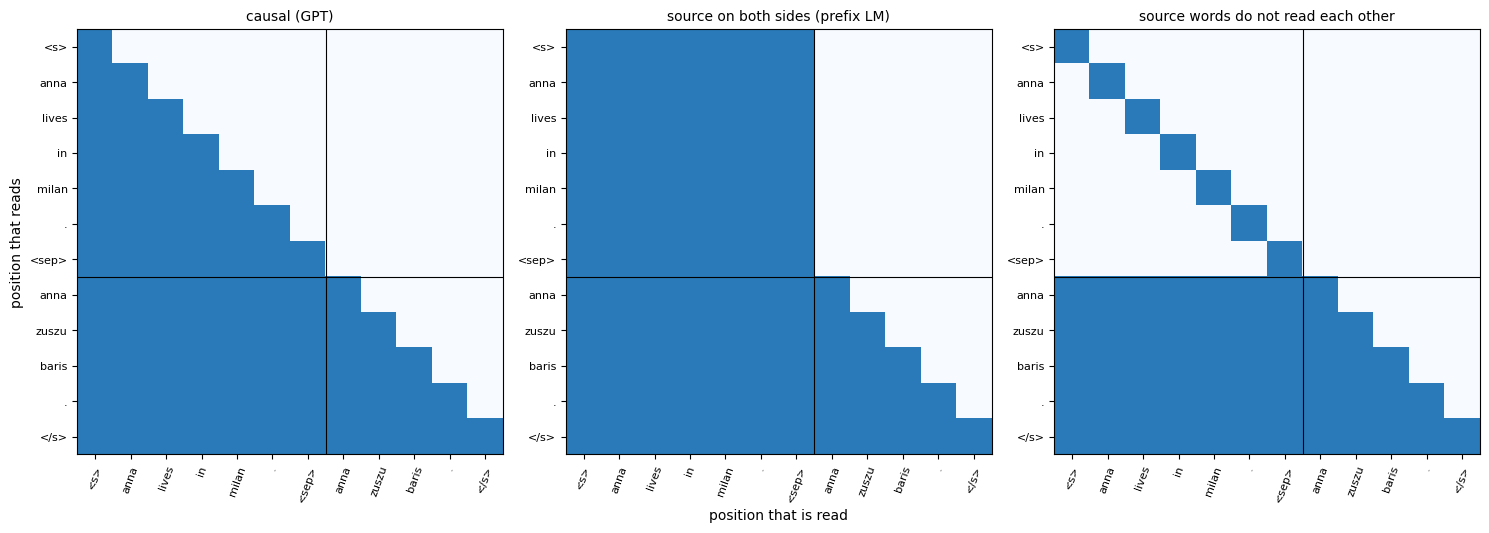

In [4]:
example = "<s> anna lives in milan . <sep> anna zuszu baris . </s>".split()
tokens = torch.tensor([vocab.encode(example)])
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, reading in zip(axes, ["causal", "bidirectional", "isolated"]):
    mask = tinylm.DecoderOnly(len(vocab), reading=reading, sep=SEP).allowed(tokens)[0]
    ax.imshow(mask, cmap="Blues", vmin=0, vmax=1.4)
    ax.set_xticks(range(len(example)), example, rotation=70, fontsize=8)
    ax.set_yticks(range(len(example)), example, fontsize=8)
    ax.axhline(example.index("<sep>") + 0.5, color="k", lw=0.8)
    ax.axvline(example.index("<sep>") + 0.5, color="k", lw=0.8)
    ax.set_title({"causal": "causal (GPT)", "bidirectional": "source on both sides (prefix LM)", "isolated": "source words do not read each other"}[reading], fontsize=10)
axes[0].set_ylabel("position that reads")
axes[1].set_xlabel("position that is read")
plt.tight_layout()
plt.show()

The code is short: the mask is built from the position of `<sep>`, and everything else is the `EncoderBlock` of L1.2, that is a block of L1.1 that takes the mask as an argument. **A decoder block is an encoder block with a triangular mask**, and the mask is the only thing that tells them apart; the same block with another mask is BERT. The cross-attention disappears because there is no second sequence to read.

In [5]:
print(inspect.getsource(tinylm.DecoderOnly.allowed))

    def allowed(self, tokens):
        # (batch, T, T): True where the row may read the column
        B, T = tokens.shape
        causal = (~torch.triu(torch.ones(T, T, dtype=torch.bool), 1))[None].expand(B, -1, -1)
        if self.reading == "causal":
            return causal
        inside = torch.arange(T)[None] <= (tokens == self.sep).int().argmax(dim=1)[:, None]      # <s> source <sep>
        both = inside[:, :, None] & inside[:, None, :]
        if self.reading == "bidirectional":
            return causal | both
        return (causal & ~both) | (both & torch.eye(T, dtype=torch.bool)[None])



## Step 3: a network without an encoder, compared with one that has it

> **A simple example.** Give the two networks the same source, `marco drinks tea . he lives in rome .`, and ask for the translation. The encoder-decoder network has a part that only reads and a part that only writes. The decoder-only network has the same blocks for reading and writing: the position of `.` after `tea` has to compute something useful about the sentence (who drinks what) so that the positions of the target can find it later, exactly as an encoder would have done. We expect that the decoder-only network can translate, and that a part of its first positions does the job of the encoder.
>
> The question of this section is: does a network without an encoder translate as well as one that has it, and is the encoder really somewhere inside it? The intuition is that the layers of the source positions are the encoder, and that if we forbid the source words to talk to each other the translation breaks.

In [6]:
trained = {}

def train_decoder(name, data, seeds, steps=1500, **kwargs):
    for seed in seeds:
        trained[name, seed] = trained_network(f"{name} seed {seed}", lambda: tinylm.fit_continuation(data, SEP, seed=seed, steps=steps, **kwargs))

def train_encoder_decoder(name, data, seeds, steps=1500):
    for seed in seeds:
        trained[name, seed] = trained_network(f"{name} seed {seed}", lambda: tinylm.fit_translation(*data, seed=seed, steps=steps))

def result(name, seed):
    model = trained[name, seed]
    row = {}
    for test in TEST_JOINED:
        if isinstance(model, tinylm.Seq2Seq):
            exact, words = tinylm.translation_accuracy(model, *TEST_SEPARATE[test])
        else:
            exact, words = tinylm.completion_accuracy(model, TEST_JOINED[test], SEP)
        row[f"{test}: sentences"], row[f"{test}: words"] = exact, words
    return row

def results(names, seeds=range(2)):
    return pd.DataFrame({f"{name}, seed {seed}": result(name, seed) for name in names for seed in seeds}).T.round(3)

train_decoder("decoder-only, 1 world", train_joined[1], [0])
train_decoder("decoder-only, 20 worlds", train_joined[20], range(2))
train_encoder_decoder("encoder-decoder, 20 worlds", train_separate[20], range(2))
results(["decoder-only, 1 world"], [0]).T.join(results(["decoder-only, 20 worlds", "encoder-decoder, 20 worlds"]).T)

decoder-only, 1 world seed 0: 57,941 parameters, final loss 0.001, loaded from the cache
decoder-only, 20 worlds seed 0: 57,941 parameters, final loss 0.001, loaded from the cache
decoder-only, 20 worlds seed 1: 57,941 parameters, final loss 0.001, loaded from the cache
encoder-decoder, 20 worlds seed 0: 65,811 parameters, final loss 0.001, loaded from the cache
encoder-decoder, 20 worlds seed 1: 65,811 parameters, final loss 0.001, loaded from the cache


,"decoder-only, 1 world, seed 0","decoder-only, 20 worlds, seed 0","decoder-only, 20 worlds, seed 1","encoder-decoder, 20 worlds, seed 0","encoder-decoder, 20 worlds, seed 1"
known world: sentences,1.000,0.999,1.0,1.0,1.0
known world: words,1.000,1.000,1.0,1.0,1.0
new world: sentences,0.000,1.000,1.0,1.0,1.0
new world: words,0.778,1.000,1.0,1.0,1.0



**The network without an encoder translates.** Trained on the 20 worlds, the decoder-only network writes exactly $100\%$ of the sentences of the new world in both seeds, and $99.9\%$ (seed 0) and $100\%$ (seed 1) of those of the known world; the encoder-decoder network of L1.2 does the same ($100\%$ everywhere). The decoder-only network has $57{,}941$ parameters, the encoder-decoder $65{,}811$. No separate encoder, no memory and no cross-attention are needed: the source is on the left of the position that writes, and the attention reads it.

The **lesson of the worlds** repeats exactly. Trained on our world alone, the decoder-only network translates $100\%$ of the sentences of the known world and $0\%$ of those of the new world, with $77.8\%$ of the words right (in L1.2: $78$-$82\%$). A network that is given the source in the text can still choose to ignore it, if what it knows of its world is enough to write the target; the accuracy on the world of training cannot tell the two cases apart, and the test has to differ from the training in what we want to measure.


In [7]:
rows = {}
for steps in (300, 500):
    train_decoder(f"decoder-only, {steps} steps", train_joined[20], range(2), steps=steps)
    train_encoder_decoder(f"encoder-decoder, {steps} steps", train_separate[20], range(2), steps=steps)
speed = results([f"{kind}, {steps} steps" for steps in (300, 500) for kind in ("decoder-only", "encoder-decoder")])
speed[["new world: sentences", "new world: words"]]

decoder-only, 300 steps seed 0: 57,941 parameters, final loss 0.841, loaded from the cache
decoder-only, 300 steps seed 1: 57,941 parameters, final loss 0.620, loaded from the cache
encoder-decoder, 300 steps seed 0: 65,811 parameters, final loss 0.189, loaded from the cache
encoder-decoder, 300 steps seed 1: 65,811 parameters, final loss 0.462, loaded from the cache
decoder-only, 500 steps seed 0: 57,941 parameters, final loss 0.054, loaded from the cache
decoder-only, 500 steps seed 1: 57,941 parameters, final loss 0.156, loaded from the cache
encoder-decoder, 500 steps seed 0: 65,811 parameters, final loss 0.009, loaded from the cache
encoder-decoder, 500 steps seed 1: 65,811 parameters, final loss 0.010, loaded from the cache


,new world: sentences,new world: words
"decoder-only, 300 steps, seed 0",0.000,0.622
"decoder-only, 300 steps, seed 1",0.000,0.707
"encoder-decoder, 300 steps, seed 0",0.502,0.972
"encoder-decoder, 300 steps, seed 1",0.024,0.869
"decoder-only, 500 steps, seed 0",0.857,0.992
"decoder-only, 500 steps, seed 1",0.075,0.924
"encoder-decoder, 500 steps, seed 0",1.000,1.000
"encoder-decoder, 500 steps, seed 1",1.000,1.000



The two networks end in the same place but not at the same time. After $500$ steps the encoder-decoder network translates $100\%$ of the sentences in both seeds (loss $0.009$ and $0.010$), the decoder-only network $85.7\%$ and $7.5\%$ (loss $0.054$ and $0.156$); after $300$ steps the encoder-decoder gets $50.2\%$ and $2.4\%$, the decoder-only $0\%$ in both (but $62$-$71\%$ of the words). At $1{,}500$ steps (the previous table) both are at $100\%$. In this task, with two seeds and one learning rate, the encoder-decoder network learns earlier. It is not a controlled comparison (the two networks have a different number of parameters and a different structure), and **we do not know why**: a possible reason is that the separate encoder is a structure that fits the task, while the decoder-only network has to find, in the same blocks, both the reading of the source and the writing of the target. We have not tested it.


### Where is the encoder?

The decoder-only network has no encoder, but it translates. Where does it read the source? The experiment of the hypothesis is to change the **mask of the source** (the top left region of the figure) and train the same network again: with the source read on both sides (as an encoder would do), and with the words of the source that cannot read each other. The target always reads everything that is on its left, source included. The network is the same (the same number of parameters), only the mask changes.

In [8]:
for reading in ("bidirectional", "isolated"):
    train_decoder(f"decoder-only, source {reading}", train_joined[20], range(2), reading=reading)
results(["decoder-only, 20 worlds", "decoder-only, source bidirectional", "decoder-only, source isolated"])[["new world: sentences", "new world: words"]]

decoder-only, source bidirectional seed 0: 57,941 parameters, final loss 0.001, loaded from the cache
decoder-only, source bidirectional seed 1: 57,941 parameters, final loss 0.001, loaded from the cache
decoder-only, source isolated seed 0: 57,941 parameters, final loss 0.131, loaded from the cache
decoder-only, source isolated seed 1: 57,941 parameters, final loss 0.131, loaded from the cache


,new world: sentences,new world: words
"decoder-only, 20 worlds, seed 0",1.000,1.000
"decoder-only, 20 worlds, seed 1",1.000,1.000
"decoder-only, source bidirectional, seed 0",1.000,1.000
"decoder-only, source bidirectional, seed 1",0.999,1.000
"decoder-only, source isolated, seed 0",0.054,0.914
"decoder-only, source isolated, seed 1",0.068,0.898



Letting the source words read each other on **both sides** changes nothing: $100\%$ and $99.9\%$ of the sentences, as with the causal mask ($100\%$ and $100\%$). In our toy every dependency of language A points to the left (a pronoun refers to a name that precedes it, a value belongs to the name of its sentence), so nothing is gained from looking right. This is the opposite of BERT in L1.3, where the hidden name could be found only from the right.

Forbidding the source words to read **each other** breaks the translation: $5.4\%$ and $6.8\%$ of the sentences are exact, with $91.4\%$ and $89.8\%$ of the words right, and the loss stays at $0.131$ instead of $0.001$. The positions of the target still read the source words, one by one, but `tea` does not know who drinks it and `he` does not know who he is. The translation needs that the source be **encoded**, that is that its positions build vectors that know the words around them, and this is done by the positions of the source, with the same blocks. A decoder-only network has an encoder, only it is not a separate part: it is the first positions of the text.


We can also look at what the target positions read. For every word that the network writes we know the word of the source that it translates (the generator writes the two documents from the same facts: the name comes from the name, the value of B from the value of A through the dictionary, the pronoun from the pronoun), and for every head of every layer we add the weight that the position puts on the **corresponding** source words, as we did for the cross-attention of L1.2. The rows are the layers and the heads, the columns the kinds of word to write, on 300 documents of the new world.

In [9]:
a2b = dict(LANGUAGE_B["lexicon"])
a2b.update({person: person for person in world.people})
a2b.update({".": ".", "</s>": "</s>"})
for relation in toyworld.RELATIONS:
    a2b[toyworld.LANGUAGE_A["question_word"][relation]] = LANGUAGE_B["question_word"][relation]
for gender, word in toyworld.LANGUAGE_A["pronouns"].items():
    a2b[word] = LANGUAGE_B["pronouns"][gender]
B_PRONOUNS, B_VALUES = set(LANGUAGE_B["pronouns"].values()), set(LANGUAGE_B["lexicon"].values())

def kind_of(word):
    return ("name" if word in world.people else "pronoun" if word in B_PRONOUNS else "value" if word in B_VALUES else
            "." if word == "." else "end" if word == "</s>" else "verb or other")

def aligned_mass(model, sequences):
    # for each (layer, head) and kind of word, the mean weight on the source words that the word translates
    rows = []
    for x in sequences:
        words = vocab.decode(x.tolist())
        cut = words.index("<sep>")
        source, target = words[1:cut], words[cut + 1:]
        source_sentence = np.cumsum([0] + [w == "." for w in source[:-1]])
        target_sentence = np.cumsum([0] + [w == "." for w in target[:-1]])
        stop = target.index("</s>") + 1
        maps = model.attention_maps(x[None, :-1])
        for j, word in enumerate(target[:stop]):
            aligned = [1 + k for k, w in enumerate(source) if source_sentence[k] == target_sentence[j] and a2b.get(w) == word]
            position = cut + j                          # the position that has to write target[j]
            for layer, m in enumerate(maps):
                for head in range(m.shape[1]):
                    weights = m[0, head, position]
                    rows.append((layer + 1, head + 1, kind_of(word), weights[aligned].sum().item() if aligned else np.nan))
    return pd.DataFrame(rows, columns=["layer", "head", "kind", "mass"])

mass = {seed: aligned_mass(trained["decoder-only, 20 worlds", seed], TEST_JOINED["new world"][:300]) for seed in range(2)}
table = pd.concat({f"seed {seed}": m.pivot_table(index=["layer", "head"], columns="kind", values="mass") for seed, m in mass.items()})
table[["name", "pronoun", "value", "verb or other", "."]].round(2)

kind               name  pronoun  value  verb or other     .
       layer head                                           
seed 0 1     1     0.04     0.01   0.11           0.03  0.06
             2     0.03     0.12   0.03           0.06  0.03
       2     1     0.05     0.06   0.04           0.05  0.04
             2     0.07     0.27   0.06           0.06  0.07
       3     1     0.07     0.43   0.16           0.02  0.02
             2     0.76     0.86   0.88           0.10  0.07
       4     1     0.01     0.04   0.01           0.04  0.01
             2     0.06     0.01   0.05           0.02  0.01
seed 1 1     1     0.04     0.03   0.04           0.02  0.04
             2     0.04     0.03   0.05           0.11  0.02
       2     1     0.67     0.31   0.57           0.11  0.16
             2     0.83     0.80   0.10           0.15  0.11
       3     1     0.07     0.06   0.46           0.08  0.07
             2     0.25     0.28   0.52           0.08  0.03
       4     1     0.03     0.04   0.07           0.03  0.02
             2     0.09     0.04   0.10           0.03  0.02


Where does the target read the source? The **first layer** and the **last one** almost never put weight on the corresponding word (at most $0.12$ in every head of both seeds): the alignment is in the middle layers. In seed 0 it is layer 3, head 2 (values $0.88$, pronouns $0.86$, names $0.76$); in seed 1 it is layer 2 (head 1 reads names $0.67$ and values $0.57$, head 2 names $0.83$ and pronouns $0.80$) and, less, layer 3 (values $0.46$ and $0.52$). The layer and the division of the work among the heads change with the seed, as in L1.2. Verbs and full stops have a low weight ($0.02$-$0.16$): the target can write them without looking at the source. In L1.2 the first block of the decoder did not align and the second did; here the first layer does not, the last one does not, and the cross-attention of the encoder-decoder is, in a sense, spread over the middle ones.

The answer to the question of the section is then in three parts. **(1)** The cross-attention is not a special piece: any position of the target can read the source with the attention it already has, and some heads of the middle layers do it as a cross-attention would. **(2)** The encoder is the source positions: if they cannot read each other the translation breaks ($5$-$7\%$ of the sentences), and if they read both sides nothing changes in this toy. **(3)** What the toy does not tell: the first layers could be the ones that prepare the source for the later ones (it agrees with the figure, but we did not test it layer by layer), and, as in L1.0, the maps say where a head looks and not where the information that the network uses comes from.


## Step 4: every word is an example

> **A simple example.** Take the document `<s> marco drinks tea . he lives in rome . </s>`. BERT hides a few of its words, say `tea` and `he`, and trains on those two: the loss is computed in two places, the other words are only read. A decoder has a question for **every position**: after `<s>` it must say `marco`, after `marco` it must say `drinks`, after `drinks` it must say `tea`, and so on up to `</s>`. The same document gives about a dozen examples instead of two. Some of them are trivial (after `lives` comes `in`), some are exactly the facts of the world (after `marco drinks`, `tea`).
>
> The question of this section is: does it matter that a decoder learns from every word, while an encoder learns from the words that have been hidden? The intuition is that the same documents, read for the same number of steps, teach more to the network that has more questions to answer, and that this is one of the reasons why the objective of the decoder is so convenient to scale.

In [10]:
doc_vocab = world.vocabulary(("A",), extra=("yes", "no"))           # yes and no are used in Step 7
DOCS = dict(n_people=2, n_facts=3)                         # the documents of L1.1 and L1.3
train_docs, test_docs = world.documents(0, 20000, **DOCS), world.documents(999, 1000, **DOCS)
doc_length = max(len(d) for d in train_docs + test_docs)
docs_train, docs_test = (torch.tensor(doc_vocab.batch(d, doc_length)) for d in (train_docs, test_docs))

generator = torch.Generator().manual_seed(0)
_, labels = tinylm.mask_tokens(docs_train[:2000], generator, vocabulary_size=len(doc_vocab))
print(f"a document has {(docs_train[:2000] != 0).sum(1).float().mean():.1f} tokens (with <s> and </s>)")
print(f"examples per document: decoder {(docs_train[:2000, 1:] != 0).sum(1).float().mean():.1f} (every token after <s>), BERT {(labels != -100).sum(1).float().mean():.1f} (15% of the words)")

a document has 29.0 tokens (with <s> and </s>)
examples per document: decoder 28.0 (every token after <s>), BERT 4.0 (15% of the words)


To compare the two objectives with a single measure we ask the same question to both: **which value does the document give to a person?** In each test document we take a value (a drink, a job, a city or a colour) and we ask for it. The decoder answers from the words on its left, which contain the name and the relation word (`marco drinks` → ?); the encoder has the value hidden and reads both sides. Everything that is needed to answer is on the left of the value, so the two questions have the same answer and the same information is available. We train two networks of four blocks for each objective and two seeds, on the same $20{,}000$ documents, with the same batch and the same number of steps, and we measure the accuracy on the values at some points of the training.

In [11]:
rng = np.random.default_rng(0)
rows = torch.arange(len(test_docs))
positions = torch.tensor([int(rng.choice([t for t, k in enumerate(world.word_kinds(d)) if k == "value"])) for d in test_docs])
answers = docs_test[rows, positions]

def lm_value_accuracy(model):
    with torch.no_grad():
        return (model(docs_test[:, :-1])[rows, positions - 1].argmax(-1) == answers).float().mean().item()

def mlm_value_accuracy(model):
    guess, _ = tinylm.fill_blank(model, docs_test, positions)
    return (guess == answers).float().mean().item()

CHECKPOINTS = (100, 200, 300, 400, 600, 800, 1200, 2000)
def train_documents_lm(seed):
    points = []
    model = tinylm.fit_lm(docs_train, seed=seed, steps=2000, layers=4, heads=2, d=32, max_length=doc_length + 2, vocabulary_size=len(doc_vocab), checkpoints=CHECKPOINTS,
                          callback=lambda step, m: points.append((step, seed, "decoder (every word)", lm_value_accuracy(m))))
    model.checkpoint_accuracy = points                          # saved with the network, to draw the curve without training again
    return model

def train_documents_mlm(seed):
    points = []
    model = tinylm.fit_mlm(docs_train, len(doc_vocab), seed=seed, steps=2000, layers=4, max_length=doc_length + 2, checkpoints=CHECKPOINTS,
                           callback=lambda step, m: points.append((step, seed, "encoder (15% hidden)", mlm_value_accuracy(m))))
    model.checkpoint_accuracy = points
    return model

documents_lm, documents_mlm, curve = {}, {}, []
for seed in range(2):
    documents_lm[seed] = trained_network(f"documents, decoder, seed {seed}", lambda: train_documents_lm(seed))
    documents_mlm[seed] = trained_network(f"documents, encoder, seed {seed}", lambda: train_documents_mlm(seed))
    curve += documents_lm[seed].checkpoint_accuracy + documents_mlm[seed].checkpoint_accuracy
table = pd.DataFrame(curve, columns=["step", "seed", "objective", "accuracy"]).pivot_table(index="step", columns=["objective", "seed"], values="accuracy")
table.round(3)

documents, decoder, seed 0: 54,967 parameters, final loss 0.490, loaded from the cache
documents, encoder, seed 0: 55,033 parameters, final loss 0.138, loaded from the cache
documents, decoder, seed 1: 54,967 parameters, final loss 0.490, loaded from the cache
documents, encoder, seed 1: 55,033 parameters, final loss 0.130, loaded from the cache


objective decoder (every word)        encoder (15% hidden)       
seed                         0      1                    0      1
step                                                             
100                      0.000  0.001                0.000  0.000
200                      0.292  0.289                0.000  0.000
300                      0.700  0.682                0.032  0.064
400                      1.000  1.000                0.201  0.315
600                      1.000  1.000                0.887  0.976
800                      1.000  1.000                0.999  1.000
1200                     1.000  1.000                0.999  1.000
2000                     1.000  1.000                1.000  1.000


The decoder has about seven times more examples per document ($28$ against $4$), and it learns the facts earlier. It answers correctly for **all** the values from step $400$ in both seeds, while the encoder is at $24\%$ and $23\%$ at that point, at $95\%$ and $99\%$ at step $600$, at $99\%$ and $100\%$ at step $800$, and at $100\%$ from step $1{,}200$. The gap in steps is a factor of about $1.5$ to $3$ (depending on the accuracy that we ask), much less than the factor of seven in the examples: most of the questions of the decoder are easy (the template words, the full stops), and only the ones about the values carry the facts of the world. Two caveats: the points are checkpoints of a single training (the learning rate is that of a schedule that ends at step $2{,}000$, not the one of a training that stops there), and the two networks are asked the question in different ways (the encoder has the value replaced by `<mask>` and reads the right side too), so this is a comparison of the objectives in this toy and not a law. What the decoder gives up is the right context; what it gains, besides the speed, is that **the objective is also the use**: to write a text the network does what it was trained for, with no change of task, and the same loss can be computed on any text without choosing which words to hide.


## Step 5: tokenization, and a name that the network has never seen

> **A simple example.** In our world `marco` is a word: the network has one row of the embedding table for it and one output for it, and `<s> marco drinks tea .` has five tokens. If a new person arrives, `zevime`, that is not in the table, the network does not know how to read it nor how to write it: it is `<unk>`. A tokenizer that cuts the words into pieces would see `ze`, `vi`, `me`, pieces that the network has met in other names, and would be able to read the new name and to copy it into the translation. The price is a longer text: `zevime` is three tokens instead of one, and the attention grows with the square of the length.
>
> The question of this section is: what does the choice of the tokens change in a decoder? The intuition is that whole words are short and cannot be applied to what they have never seen, characters can be applied to everything and are long, and BPE, which L0.1 introduced as a compromise, sits in between.

GPT-2 uses a **byte-level BPE** with $50{,}257$ tokens (we see it in Step 10), and BPE is the choice of almost all the decoders. We train our network to translate with three kinds of token: **whole words** (what we used so far), **characters**, and **BPE** with two vocabulary sizes. The BPE is the `BPETokenizer` of L0.1, trained on the words of the training set; each word is closed by a marker `_` so that the end of a word can be recovered (the original BPE does the same with `</w>`). To see what happens to a name that was never seen, we change the experiment in one thing: the names of the people are **invented** (a pool of $240$ for the training and $60$ never used in the training), the worlds are many and small (two people each, $2{,}000$ worlds, so that a name tells nothing about the facts) and the texts are shorter (one person and two facts, to keep the characters affordable). The test: the translation of a document in which the name is one of the training names, and of one in which the name is a new one. The name is copied from A to B, so the network has to learn to **copy** a sequence of pieces that it may never have seen.

In [12]:
from nlp import bpe

avoid = set(vocab.words) | set(toyworld.NAMES)
rng = np.random.default_rng(5)
def new_name():
    while True:
        name = "".join(rng.choice(list("bdfgklmnprstvz")) + rng.choice(list("aeiou")) for _ in range(rng.integers(2, 4)))
        if name not in avoid:
            avoid.add(name)
            return name
pool = [new_name() for _ in range(300)]
train_names, new_names = pool[:240], pool[240:]
print("examples of names:", train_names[:5], "| never used in the training:", new_names[:5])

SHORT = dict(n_people=1, n_facts=2)
def name_pairs(names, n_worlds, size, seed):
    r = np.random.default_rng(seed)
    pairs = []
    for k in range(n_worlds):
        two = tuple(str(x) for x in r.choice(names, 2, replace=False))
        w = toyworld.ToyWorld(toyworld.WorldConfig(n_people=2, seed=k, names=two), language_b=LANGUAGE_B)
        pairs += w.translation(1000 * seed + k, size // n_worlds, **SHORT)
    return pairs

name_train = joined(name_pairs(train_names, 2000, 20000, 1))
name_test = {"known names": joined(name_pairs(train_names, 1, 500, 2)), "new names": joined(name_pairs(new_names, 1, 500, 3))}
print(" ".join(name_train[0]))

examples of names: ['tatino', 'zage', 'lababa', 'fosegi', 'zavo'] | never used in the training: ['beno', 'vifo', 'tezise', 'luveke', 'bomu']
<s> zevime likes brown . he is a nurse . <sep> kesva duzul zevime . rerfur pumus vudas . </s>


In [13]:
SPECIAL = set(toyworld.SPECIALS) | {"."}

def make_tokenization(kind, size=None):
    # returns the vocabulary and the function that cuts a list of words into a list of pieces
    if kind == "words":
        return toyworld.Vocabulary(sorted({w for t in name_train for w in t})), (lambda words: words)
    corpus = [" ".join(w + "_" for w in t if w not in SPECIAL) for t in name_train[:5000]]
    if kind == "characters":
        alphabet = sorted({ch for text in corpus for ch in text if ch != " "})
        cut = lambda w: list(w + "_")
    else:
        tokenizer = bpe.BPETokenizer(vocab_size=size).fit(corpus)
        alphabet = sorted(tokenizer.vocab)
        cut = lambda w: tokenizer.tokenize_words(w + "_")[0]
    return toyworld.Vocabulary(alphabet + ["."]), (lambda words: [p for w in words for p in ([w] if w in SPECIAL else cut(w))])

CONFIGS = [("words", "words", None, [0]), ("characters", "characters", None, [0, 1]), ("BPE, 120 pieces", "bpe", 120, [0, 1]), ("BPE, 250 pieces", "bpe", 250, [0, 1])]
rows = []
for label, kind, size, seeds in CONFIGS:
    token_vocab, cut = make_tokenization(kind, size)
    sep = token_vocab.encode(["<sep>"])[0]
    as_tensor = lambda texts: torch.tensor(token_vocab.batch([cut(t) for t in texts]))
    train_t, test_t = as_tensor(name_train), {k: as_tensor(v) for k, v in name_test.items()}
    length = max([train_t.shape[1]] + [t.shape[1] for t in test_t.values()])
    pad = lambda x: F.pad(x, (0, length - x.shape[1]))
    train_t, test_t = pad(train_t), {k: pad(v) for k, v in test_t.items()}
    pieces = lambda names: np.mean([len(cut([n])) for n in names])
    for seed in seeds:
        model = trained_network(f"names, {label}, seed {seed}", lambda: tinylm.fit_continuation(train_t, sep, seed=seed, steps=1500, max_length=length))
        row = {"tokens": label, "seed": seed, "vocabulary": len(token_vocab), "tokens per text": (train_t != 0).sum(1).float().mean().item(),
               "pieces per known name": pieces(train_names), "pieces per new name": pieces(new_names), "parameters": model.n_parameters()}
        for test, tokens in test_t.items():
            row[f"{test}: sentences"], row[f"{test}: words"] = tinylm.completion_accuracy(model, tokens, sep)
        rows.append(row)
pd.DataFrame(rows).set_index(["tokens", "seed"]).round(3)

names, words, seed 0: 71,385 parameters, final loss 0.005, loaded from the cache
names, characters, seed 0: 55,360 parameters, final loss 0.010, loaded from the cache
names, characters, seed 1: 55,360 parameters, final loss 0.035, loaded from the cache
names, BPE, 120 pieces, seed 0: 60,383 parameters, final loss 0.006, loaded from the cache
names, BPE, 120 pieces, seed 1: 60,383 parameters, final loss 0.010, loaded from the cache
names, BPE, 250 pieces, seed 0: 68,513 parameters, final loss 0.006, loaded from the cache
names, BPE, 250 pieces, seed 1: 68,513 parameters, final loss 0.005, loaded from the cache


vocabulary  tokens per text  pieces per known name  \
tokens          seed                                                       
words           0            313           19.998                  1.000   
characters      0             32           80.850                  6.058   
                1             32           80.850                  6.058   
BPE, 120 pieces 0            127           38.065                  4.125   
                1            127           38.065                  4.125   
BPE, 250 pieces 0            257           27.861                  3.792   
                1            257           27.861                  3.792   

                      pieces per new name  parameters  known names: sentences  \
tokens          seed                                                            
words           0                   1.000       71385                   1.000   
characters      0                   5.733       55360                   0.886   
                1                   5.733       55360                   0.508   
BPE, 120 pieces 0                   3.917       60383                   1.000   
                1                   3.917       60383                   1.000   
BPE, 250 pieces 0                   3.750       68513                   1.000   
                1                   3.750       68513                   1.000   

                      known names: words  new names: sentences  \
tokens          seed                                             
words           0                  1.000                 0.000   
characters      0                  0.951                 0.856   
                1                  0.849                 0.486   
BPE, 120 pieces 0                  1.000                 0.758   
                1                  1.000                 0.562   
BPE, 250 pieces 0                  1.000                 0.472   
                1                  1.000                 0.286   

                      new names: words  
tokens          seed                    
words           0                0.854  
characters      0                0.961  
                1                0.829  
BPE, 120 pieces 0                0.846  
                1                0.893  
BPE, 250 pieces 0                0.584  
                1                0.459


**Whole words** cannot do it, by construction: a new name is `<unk>` at the input and the network has no way to write it; in the table no sentence with a new name is exact ($0\%$), though $85.4\%$ of the words are right (the ones that do not depend on the name). **Characters** and **BPE** can read and write the new name, because it is made of pieces that the network has met, but how well they do it is **uncertain**: BPE with $120$ pieces gets $75.8\%$ (seed 0) and $56.2\%$ (seed 1) of the sentences exact with new names, against $100\%$ with the known ones; BPE with $250$ pieces, which merges more, $47.2\%$ and $28.6\%$. A prototype outside the notebook (other training length) gave the opposite order for the two sizes and the same spread between the seeds ($18\%$ and $100\%$ for $250$ pieces in two seeds), so the ranking of the two BPE vocabularies is **not** a result; what is stable is the ordering between words and subwords. The characters need more training than we gave them: after $1{,}500$ steps the known names are not exact either ($88.6\%$ and $50.8\%$), because a text has $81$ tokens instead of $20$ and the attention grows with the square of the length; for them the new names are as good as the known ones ($85.6\%$ and $48.6\%$), as they should. The cost of the pieces is in the columns on the left: a text goes from $20$ tokens to $38$ (BPE 120), $28$ (BPE 250), $81$ (characters), and a name from one token to $3.9$, $3.75$ or $5.7$. The vocabulary shrinks from $313$ words to $127$, $257$ or $32$ symbols. Why the networks with pieces copy a new name only in part, and why it depends on the seed, we did not test.


## Step 6: a vector for the whole text

> **A simple example.** We want one vector for the document `<s> marco drinks tea . he lives in rome . </s>`: a vector that we can compare with the vector of another document, or give to a classifier. In BERT (L1.3) the vector of `<s>` is the natural choice: the position reads the whole text on both sides. In a decoder the position of `<s>` reads only itself, so its vector is the same for every document. The only position that has read the whole text is the last one, `</s>`; but that position was never trained to summarize anything, it was trained to say what comes next. We could also take the average of the vectors of all the positions, but the position of `marco` has read only `<s> marco`. And there are the layers: the vector of the first one is close to the words, the one of the last is built to predict a word.
>
> The question of this section is: where do we take the vector of a text from a decoder? The intuition is that the answer is a choice, with three degrees of freedom (the position, the way of combining the positions, the layer), and that the choice changes how much of the text we find in the vector.

We keep the networks of Step 4, already trained and **frozen**, and we ask how much of the text is in the vector with a **probe**: a linear map, trained on $4{,}000$ documents, that predicts a property of the text from the vector alone, and tested on $1{,}000$ other documents. If the probe succeeds, the information is in the vector, in a form that a linear classifier can read. The properties are two facts of the text, taken far from each other: the **value of the first sentence** and the **value of the last sentence** (26 classes: the values of the drinks, jobs, cities and colours). They are the content of the document at the two ends: a good vector of the whole text has to keep both. The probe is a regression on the one-hot label (a closed formula, so that it can be repeated for every choice); the two networks are the decoder and the encoder of Step 4, the same size and the same documents.

We compare four ways of taking the vector: the **first token** (`<s>`, the `[CLS]` of BERT), the **last token** (`</s>`), the **last word** (the final full stop, the last position that has a word to predict), and the **mean** of the vectors of all the positions; and the vector at the entrance (layer 0: word and position) and after each of the four blocks (layer 4 is the one that the output layer reads).

In [14]:
OPT_PROBE = DOCS
probe_train, probe_test = world.documents(1, 4000, **OPT_PROBE), world.documents(2, 1000, **OPT_PROBE)
probe_x_train, probe_x_test = (torch.tensor(doc_vocab.batch(d, doc_length)) for d in (probe_train, probe_test))
classes = sorted({v for values in world.values.values() for v in values})
index = {c: i for i, c in enumerate(classes)}
value_of = lambda doc, which: doc[world.sentences(doc)[which]["end"] - 1]
TARGETS = {"first sentence": 0, "last sentence": -1}
labels = {name: (torch.tensor([index[value_of(d, which)] for d in probe_train]), torch.tensor([index[value_of(d, which)] for d in probe_test]))
          for name, which in TARGETS.items()}
print(len(classes), "classes; the most frequent class is", {name: round(float(torch.bincount(y[1]).max() / len(y[1])), 3) for name, y in labels.items()}, "of the test documents")

def take(states, tokens, where):
    # the vector of each document, from the states of every layer
    real = tokens != 0
    n = real.sum(1)
    pick = {"first token": lambda h: h[:, 0], "last token": lambda h: h[torch.arange(len(h)), n - 1],
            "last word": lambda h: h[torch.arange(len(h)), n - 2], "mean of all positions": lambda h: (h * real[..., None]).sum(1) / n[:, None]}[where]
    return [pick(h) for h in states]

def probe(train_vectors, train_labels, test_vectors, test_labels, ridge=1.0):
    # linear map to the one-hot label (closed formula), standardized inputs; accuracy of the largest score
    mean, std = train_vectors.mean(0), train_vectors.std(0) + 1e-6
    add_one = lambda x: torch.cat([(x - mean) / std, torch.ones(len(x), 1)], 1)
    A, B = add_one(train_vectors), add_one(test_vectors)
    W = torch.linalg.solve(A.T @ A + ridge * torch.eye(A.shape[1]), A.T @ F.one_hot(train_labels, len(classes)).float())
    return ((B @ W).argmax(1) == test_labels).float().mean().item()

rows = []
for seed in range(2):
    for name, model in (("decoder", documents_lm[seed]), ("encoder", documents_mlm[seed])):
        states_train, states_test = tinylm.hidden_states(model, probe_x_train), tinylm.hidden_states(model, probe_x_test)
        for where in ("first token", "last token", "last word", "mean of all positions"):
            vectors_train, vectors_test = take(states_train, probe_x_train, where), take(states_test, probe_x_test, where)
            for layer in range(len(vectors_train)):
                for target, (y_train, y_test) in labels.items():
                    rows.append((name, where, layer, target, seed, probe(vectors_train[layer], y_train, vectors_test[layer], y_test)))
probes = pd.DataFrame(rows, columns=["network", "where", "layer", "target", "seed", "accuracy"])
spread = probes.groupby(["network", "where", "layer", "target"])["accuracy"].agg(lambda x: x.max() - x.min())
print(f"the two seeds differ by {spread.median():.2f} (median) and by {spread.max():.2f} (at most) in the cells below")
for target in TARGETS:
    print(f"\nvalue of the {target}")
    display(probes[probes["target"] == target].pivot_table(index=["network", "where"], columns="layer", values="accuracy").round(2).style.background_gradient(cmap="Blues", vmin=0, vmax=1).format("{:.2f}"))

26 classes; the most frequent class is {'first sentence': 0.084, 'last sentence': 0.084} of the test documents
the two seeds differ by 0.03 (median) and by 0.32 (at most) in the cells below

value of the first sentence



value of the last sentence



How to read the tables: each cell is the accuracy of the probe ($0.08$ is the share of the most frequent class, the chance level), the average of two seeds; the two seeds differ by $0.03$ in the median cell but by $0.31$ in the worst one, so **only large differences are an indication**.

* **The first token of a decoder is useless**, by construction: it reads only itself, and its vector is the same for every text ($0.08$ in all layers, for both targets).
* **For the decoder, the mean of all the positions is the best way to take a vector** for the content at the beginning of the text: $0.62$-$0.74$ for the first sentence in the layers 1-4, against $0.26$-$0.29$ for the last token and $0.27$-$0.46$ for the last word. The last token and the last word keep less of what is far away; for the last sentence, the one that has just been read, the three ways are close ($0.37$-$0.53$) and the differences are within the spread of the seeds.
* **The layer matters.** At layer 0 (words and positions only) the mean is a bag of words and gives $0.23$ and $0.21$; the blocks add who has what, and the probe goes up to $0.74$ and $0.53$. And **the last layer is not the best one**: for the mean of the decoder the first sentence goes from $0.74$ (layer 3) to $0.62$ (layer 4); for the mean of the encoder from $0.58$ to $0.44$. The last layer is built to predict a word, not to keep the text. For the last word of the decoder the opposite happens for the first sentence (it grows with the layers, $0.27$, $0.31$, $0.38$, $0.46$), and we do not know why.
* **For the encoder the first token is not a summary either**: it is the best position for the last sentence ($0.57$-$0.61$ in the layers 1-3) and the worst for the first ($0.20$-$0.27$). No loss was ever computed on the `<s>` of the MLM: as in L1.3, the `[CLS]` becomes a summary only when a classification head is trained on it.
* **Nothing above $0.74$**: frozen vectors of networks trained to predict a word are not good summaries of the text, whatever the position and the layer. The information is there, in different amounts, and **where to take it is a choice that changes the answer by a factor of two or three**.

These are results on our toy networks, and we do not claim that they carry over to the real models. What carries over is the question: a decoder computes a vector at every position and in every layer, and which of them stands for the whole text has to be chosen.


## Step 7: classification with a network that only writes

> **A simple example.** In our world `marco drinks coffee`. The text `marco drinks tea` is false. BERT (L1.3) decides with a head on `[CLS]`. A decoder has neither the head nor the position: all it can do is to say which word comes next. But a network that has learned the world finds `marco drinks tea` *surprising*: after `marco drinks` it expected `coffee`, and `tea` had a very small probability. That probability is already a score. A second way: write after the text a separator and let the network say `yes` or `no`, as if the label were a word of the language. A third way: put in the text, before the one to judge, a few documents each with its label, and let the network go on writing the list.
>
> The question of this section is: how does a network that only writes words classify? The intuition is that **every way uses nothing but the next-word prediction**: the score is the probability of the text, the label is a word, the training examples are part of the text.

### First way: the probability of the text

A decoder is a model of the probability of a text, $P(z_1 \dots z_T) = \prod_t P(z_t \mid z_{<t})$, and a text that contradicts the world has a smaller probability than one that agrees with it. This is the idea of the classifier of L0.7, where a language model for each class and Bayes' rule gave a classifier. Here there is one model (trained on **true** documents only, the networks of Step 4) and one number to compute, the log-probability of the text. We use it on the task of L1.3 (is the document true or false?) with three scores: the sum of the log-probabilities of all the words, the mean per word, and the log-probability of the **worst word**, the one that the network finds most surprising. A single parameter has to be set, a threshold, and we choose it on $1{,}000$ labelled documents (the labels are not used to train the network, only to put the cut); the accuracy is measured on $2{,}000$ other documents.

In [15]:
val_docs, val_labels = world.verification(5, 1000, **DOCS)
test_verification, test_labels = world.verification(99, 2000, **DOCS)
as_tokens = lambda docs: torch.tensor(doc_vocab.batch(docs, doc_length + 2))
x_val, x_verify = as_tokens(val_docs), as_tokens(test_verification)
y_val, y_verify = torch.tensor(val_labels), torch.tensor(test_labels)

def word_log_probabilities(model, x):
    # log P(word | words before) for every word after <s> (0 on the padding)
    with torch.no_grad():
        log_p = model(x[:, :-1]).log_softmax(dim=-1).gather(-1, x[:, 1:, None])[..., 0]
    return log_p.masked_fill(x[:, 1:] == 0, 0.0)

SCORES = {"sum of the log-probabilities": lambda lp, x: lp.sum(1),
          "mean per word": lambda lp, x: lp.sum(1) / (x[:, 1:] != 0).sum(1),
          "worst word": lambda lp, x: lp.min(1).values}

def best_threshold(score, y):
    candidates = score.sort().values
    return candidates[torch.stack([((score > c).long() == y).float().mean() for c in candidates]).argmax()]

rows = {}
for seed in range(2):
    lp_val, lp_test = word_log_probabilities(documents_lm[seed], x_val), word_log_probabilities(documents_lm[seed], x_verify)
    for name, score in SCORES.items():
        threshold = best_threshold(score(lp_val, x_val), y_val)
        rows.setdefault(name, {})[f"seed {seed}"] = ((score(lp_test, x_verify) > threshold).long() == y_verify).float().mean().item()
lp = word_log_probabilities(documents_lm[0], x_verify)
print(f"total log-probability of the test documents (seed 0): true {lp[y_verify == 1].sum(1).mean():.1f}, false {lp[y_verify == 0].sum(1).mean():.1f}")
pd.DataFrame(rows).T.round(3)

total log-probability of the test documents (seed 0): true -13.8, false -23.9


,seed 0,seed 1
sum of the log-probabilities,0.999,0.999
mean per word,0.998,0.999
worst word,0.999,0.999



The probability of the text classifies the test documents with an accuracy of $99.9\%$ in both seeds with the sum of the log-probabilities and with the worst word ($99.8\%$ and $99.9\%$ with the mean per word), after fixing a single threshold. The total log-probability of a true document is on average $-13.8$ and that of a false one $-23.9$ (seed 0): a wrong value is a very improbable word at one position, and it costs about ten nats. The network was never trained to tell true from false: it was trained on true documents only, and the $1{,}000$ labelled documents served only to place the threshold. The value is above the ones of the BERT of L1.3 ($0.996$ and $0.928$ pre-trained on $20{,}000$ labelled documents), though the networks and the training are not the same. Limits: the false documents are of one kind only (one value replaced by another of the same relation), and the threshold needs some labelled documents.


### Second way: the label is a word

The network can also be **trained** to answer. We append to the document the separator and a word, `yes` or `no`, and we train with the loss on that word only (`fit_targets`, a loss that counts the positions that we mark). It is the fine-tuning of L1.3, with a difference that matters: there is **no head** and no special position. The answer is read in the position of `<sep>`, which is the last one, the only one that has read all the document. We compare the network that starts from the one pre-trained on the documents (Step 4) with the same network started from scratch, on $20{,}000$ labelled documents, two seeds.

In [16]:
YES, NO = doc_vocab.encode(["yes"])[0], doc_vocab.encode(["no"])[0]

def labelled(docs, labels):
    sequences = [d + ["<sep>", "yes" if label else "no"] for d, label in zip(docs, labels)]
    x = torch.tensor(doc_vocab.batch(sequences, doc_length + 2))
    target = torch.zeros_like(x)
    target[torch.arange(len(x)), (x != 0).sum(1) - 1] = 1                        # only the word after <sep> counts
    return x, target

def label_accuracy(model, docs, labels):
    x, _ = labelled(docs, labels)
    with torch.no_grad():
        scores = model(x[:, :-1])[torch.arange(len(x)), (x != 0).sum(1) - 2]       # the position of <sep> says the label
    return ((scores[:, YES] > scores[:, NO]).long() == torch.tensor(labels)).float().mean().item()

fine_docs, fine_labels = world.verification(6, 20000, **DOCS)
x_fine, target_fine = labelled(fine_docs, fine_labels)
rows = {}
for seed in range(2):
    for name, init in (("pre-trained on the documents", documents_lm[seed].state_dict()), ("from scratch", None)):
        model = trained_network(f"fine-tuned, {name}, seed {seed}", lambda: tinylm.fit_targets(
            x_fine, target_fine, seed=seed, steps=2000, batch_size=64, init=init, vocabulary_size=len(doc_vocab), layers=4, heads=2, d=32, max_length=doc_length + 2))
        rows.setdefault(name, {})[f"seed {seed}"] = label_accuracy(model, test_verification, test_labels)
pd.DataFrame(rows).T.round(3)

fine-tuned, pre-trained on the documents, seed 0: 54,967 parameters, final loss 0.425, loaded from the cache
fine-tuned, from scratch, seed 0: 54,967 parameters, final loss 0.501, loaded from the cache
fine-tuned, pre-trained on the documents, seed 1: 54,967 parameters, final loss 0.063, loaded from the cache
fine-tuned, from scratch, seed 1: 54,967 parameters, final loss 0.447, loaded from the cache


,seed 0,seed 1
pre-trained on the documents,0.789,0.984
from scratch,0.719,0.757



The network pre-trained on the documents reaches $0.789$ (seed 0) and $0.984$ (seed 1), the one started from scratch $0.719$ and $0.757$. Pre-training is better in both seeds, but the two seeds of the pre-trained network differ by $0.2$: with $2{,}000$ steps the fine-tuning is unstable (in a prototype outside the notebook, $3{,}000$ steps took a seed to $0.89$). These numbers are in the range of the ones of L1.3 ($0.996$ and $0.928$ pre-trained, $0.733$ and $0.790$ from scratch), with other networks and a different training, so it is not a controlled comparison; what we can say is that a decoder, with **no head and no special position**, can be fine-tuned to classify: the position that has read the whole text is the last one instead of the first. The probability of the text, above, does better than both and trains nothing on the labels.


### Third way: the examples are in the text (in-context learning)

> **A simple example.** We want to classify the sentences of our world by what they tell: `marco lives in naples .` tells a city, `luca is a mechanic .` a job, `sara likes red .` a colour, `marco drinks coffee .` a drink. We do not tell the network which symbol stands for which kind; we show it a few cases and ask for one more: `<s> anna lives in milan . C ; luca is a mechanic . A ; sara likes red . D ; marco lives in naples .` and the network has to write the symbol of the last sentence. The examples say that a sentence like `anna lives in milan .` gets `C`, so the answer is `C`. In another prompt the cities could be `A`, or `B`: the symbols are assigned in a different way each time, and the only place where the assignment can be found is the prompt.
>
> The question of this section is: can the network learn the rule of a classification **from the text of the prompt**, without changing any weight? The intuition is that the prompt is a short training set, and that the network can read it with the attention, as in L1.0 it read who drinks what in a list.

In the previous ways the weights were trained (the whole network, or only the threshold) for one task. Here the weights are fixed and the task is in the text: a *prompt* of $k$ demonstrations, each a sentence of the world followed by its symbol, and then a sentence without the symbol. This is **in-context learning**, the behaviour of the large language models that made the decoders popular (Brown et al., 2020). In the real models it **emerges** from training on the next word of a huge variety of texts; in the toy it does not emerge, we **build** it: we train the network on prompts, each with a different random assignment of the four symbols to the four kinds of sentence, so that the only way to be right is to read the assignment in the demonstrations. We say it clearly: this is a construction, and the question of the section is whether the network that we obtain generalizes to assignments that it has never seen. We keep $6$ of the $24$ assignments out of the training, and we compare with a network trained on only $3$ assignments. The loss counts every symbol of the prompt (the first symbol of a prompt cannot be predicted, the others can).

In [17]:
import itertools

SYMBOLS = ["A", "B", "C", "D"]
icl_vocab = world.vocabulary(("A",), extra=SYMBOLS + [";"])
facts = [(person, relation) for person in world.people for relation in toyworld.RELATIONS]
sentence_of = {f: world.say(world.fact(*f)) for f in facts}
relation_index = {r: i for i, r in enumerate(toyworld.RELATIONS)}
assignments = list(itertools.permutations(range(4)))                    # symbol of each kind of sentence
order = np.random.default_rng(0).permutation(len(assignments))
seen_assignments, new_assignments = [assignments[i] for i in order[:18]], [assignments[i] for i in order[18:]]

def make_prompts(n, seed, pool, demonstrations=range(9)):
    r = np.random.default_rng(seed)
    texts, marks, shown = [], [], []
    for _ in range(n):
        assignment, k = pool[r.integers(len(pool))], int(r.choice(list(demonstrations)))
        words, mark = ["<s>"], [0]
        for j in range(k + 1):
            f = facts[r.integers(len(facts))]
            words += sentence_of[f] + [SYMBOLS[assignment[relation_index[f[1]]]]]
            mark += [0] * len(sentence_of[f]) + [1]
            if j < k:
                words.append(";")
                mark.append(0)
        texts.append(words), marks.append(mark), shown.append(k)
    length = max(len(t) for t in texts)
    x = torch.tensor(icl_vocab.batch(texts, length))
    target = torch.zeros(len(texts), length, dtype=torch.long)
    for i, mark in enumerate(marks):
        target[i, :len(mark)] = torch.tensor(mark)
    return x, target, torch.tensor(shown)

def query_accuracy(model, x, shown):
    # the accuracy of the last symbol of each prompt (the one asked), by number of demonstrations
    n = (x != 0).sum(1)
    with torch.no_grad():
        guess = model(x[:, :-1]).argmax(-1)[torch.arange(len(x)), n - 2]
    return pd.Series((guess == x[torch.arange(len(x)), n - 1]).float().numpy()).groupby(shown.numpy()).mean()

x_prompts, target_prompts, _ = make_prompts(20000, 1, seen_assignments)
x_few, target_few, _ = make_prompts(20000, 1, seen_assignments[:3])
print(" ".join(icl_vocab.decode(x_prompts[0][x_prompts[0] != 0].tolist())))

<s> mario drinks water . D ; carlo is a farmer . C ; anna is a farmer . C ; marco lives in naples . B ; mario likes yellow . A


in-context, 18 assignments in the training: 111,098 parameters, final loss 0.504, loaded from the cache
in-context, 3 assignments in the training: 111,098 parameters, final loss 0.203, loaded from the cache


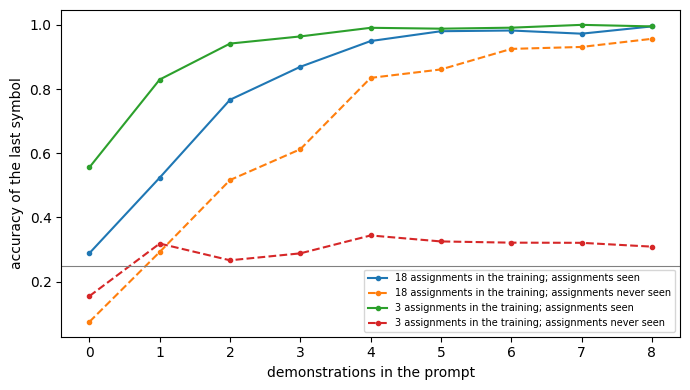

18 assignments in the training                         \
                             assignments seen assignments never seen   
demonstrations                                                         
0                                        0.29                   0.07   
1                                        0.52                   0.29   
2                                        0.77                   0.52   
3                                        0.87                   0.61   
4                                        0.95                   0.83   
5                                        0.98                   0.86   
6                                        0.98                   0.93   
7                                        0.97                   0.93   
8                                        1.00                   0.96   

               3 assignments in the training                         
                            assignments seen assignments never seen  
demonstrations                                                       
0                                       0.56                   0.16  
1                                       0.83                   0.32  
2                                       0.94                   0.27  
3                                       0.96                   0.29  
4                                       0.99                   0.34  
5                                       0.99                   0.33  
6                                       0.99                   0.32  
7                                       1.00                   0.32  
8                                       1.00                   0.31

In [18]:
icl = {}
for name, (x, target) in {"18 assignments in the training": (x_prompts, target_prompts), "3 assignments in the training": (x_few, target_few)}.items():
    icl[name] = trained_network(f"in-context, {name}", lambda: tinylm.fit_targets(
        x, target, seed=0, steps=3000, layers=2, heads=4, d=64, max_length=x.shape[1], vocabulary_size=len(icl_vocab)))

curves = {}
for name, model in icl.items():
    pool_seen = seen_assignments if name.startswith("18") else seen_assignments[:3]
    for kind, pool in (("assignments seen", pool_seen), ("assignments never seen", new_assignments)):
        x, _, shown = make_prompts(2000, 7, pool)
        curves[name, kind] = query_accuracy(model, x, shown)
curves = pd.DataFrame(curves)
curves.index.name = "demonstrations"
fig, ax = plt.subplots(figsize=(7, 4))
for (name, kind), values in curves.items():
    ax.plot(values.index, values, marker="o", ms=3, ls="-" if kind == "assignments seen" else "--", label=f"{name}; {kind}")
ax.axhline(0.25, color="gray", lw=0.8)
ax.set_xlabel("demonstrations in the prompt"); ax.set_ylabel("accuracy of the last symbol"); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
curves.round(2)


**The weights are the same at every point of the curves; what changes is the prompt.** The network trained on $18$ assignments of the symbols, on assignments it **never saw**, goes from $0.07$ with no demonstration (below the $0.25$ of chance: with no information it answers with the symbol of the assignments that it knows) to $0.29$, $0.52$, $0.61$ and $0.83$ with one, two, three and four demonstrations, and $0.96$ with eight; on the assignments seen in training the curve goes from $0.29$ to $1.00$. With one demonstration the network knows the symbol of one kind of sentence only; with four or more it has seen almost all the kinds.

The network trained on **3** assignments only is the opposite case. On those it is excellent ($0.56$ with no demonstration, $1.00$ with eight), but on new assignments it stays at $0.27$-$0.34$ with any number of demonstrations ($0.31$ with eight): it has not learned to read the assignment in the prompt, it has learned three assignments (we did not look inside to see how it chooses one). It is the lesson of the worlds of L1.2 again: the examples of a task do not make the network learn a rule if the training offers it too few, and **the variety of the tasks seen in training is what makes in-context learning possible**. Limits: one seed for each network, and a network that was trained for this: we built the ability, it did not emerge. In the real models the variety comes from the texts of the web (a point we take from the literature and not from our experiments).


## Step 8: choosing the next word

> **A simple example.** At the start of a document, after `<s>`, our network gives a probability to each of the twelve names. If we take the most probable every time we write **always the same document**; if we sample from the distribution, we write documents that are all different and that are almost always true; if we sample from a distribution that has been flattened (a high temperature), a name can be followed by something that the world does not say. Between the two there are ways to keep the sampling and cut the unlikely words.
>
> The question of this section is: given the distribution of the next word, how do we choose a word, and what does the choice change in what we write? The intuition is that there is a trade-off between **variety** and **fidelity**: a good rule has to let the network write different texts and not let it write what it finds improbable.

The network gives, at each step, scores $s_w$ for every word. The rules that we compare differ in how they turn them into a choice:

* **greedy**: the word with the largest score;
* **temperature** $\tau$: sampling from $\mathrm{softmax}(s / \tau)$; $\tau < 1$ sharpens the distribution (it tends to the greedy choice), $\tau > 1$ flattens it;
* **top-$k$**: sampling only among the $k$ most probable words (the others are cut and the rest renormalized);
* **top-$p$** (*nucleus sampling*): sampling among the smallest set of most probable words whose probability adds up to $p$; the number of words kept changes with the step, few when the network is sure and many when it is not.

All of them are applied to the scores of the **next** word, one step at a time. The code is a few lines.

In [19]:
print(inspect.getsource(tinylm.choose_next))

def choose_next(scores, temperature=1.0, top_k=0, top_p=1.0, generator=None):
    # one word per row of `scores` (batch, vocabulary): temperature, then top-k (keep the k best, 0 = all), then top-p (keep the
    # smallest set of best words whose probability reaches p), then sampling. temperature=0 gives the most probable word.
    if temperature == 0:
        return scores.argmax(dim=-1)
    scores = scores / temperature
    if top_k:
        kth = scores.topk(top_k, dim=-1).values[:, -1:]
        scores = scores.masked_fill(scores < kth, float("-inf"))
    if top_p < 1.0:
        order = scores.argsort(dim=-1, descending=True)
        sorted_probs = scores.gather(-1, order).softmax(dim=-1)
        before = sorted_probs.cumsum(dim=-1) - sorted_probs                  # probability of the words that come first
        drop = torch.zeros_like(scores, dtype=torch.bool).scatter(-1, order, before >= top_p)
        scores = scores.masked_fill(drop, float("-inf"))
    return torch.multinomial(

To compare the rules we write $300$ documents from `<s>` with the network of seed 0 of Step 4, with temperature $0.7$, $1$, $1.5$, $2$ and the three filters, and we measure three things: the share of documents that **end** with `</s>` within the length of the network, the share of those that end that are **true** in the world (a document that is not well formed counts as not true), and the share of **distinct** texts among the $300$.

In [20]:
def is_true_text(words):
    try:
        return world.is_true(words)
    except (ValueError, KeyError, IndexError):                    # not a document of the world
        return False

def write_and_measure(model, n=300, **options):
    texts = tinylm.write_texts(model, [1], n, 40, seed=0, **options)
    written = [doc_vocab.decode([w for w in t.tolist() if w != 0]) for t in texts]
    ended = [w for w in written if w[-1] == "</s>"]
    return {"ended": len(ended) / n, "true, among those that ended": sum(map(is_true_text, ended)) / max(len(ended), 1), "distinct texts": len({tuple(w) for w in written}) / n}

rows = {("greedy", ""): write_and_measure(documents_lm[0], temperature=0)}
for temperature in (0.7, 1.0, 1.5, 2.0):
    for name, options in (("no filter", {}), ("top-k = 3", dict(top_k=3)), ("top-p = 0.9", dict(top_p=0.9))):
        rows[f"temperature {temperature}", name] = write_and_measure(documents_lm[0], temperature=temperature, **options)
pd.DataFrame(rows).T.round(3)

ended  true, among those that ended  \
greedy                       1.000                         1.000   
temperature 0.7 no filter    1.000                         0.993   
                top-k = 3    1.000                         0.997   
                top-p = 0.9  1.000                         1.000   
temperature 1.0 no filter    0.993                         0.943   
                top-k = 3    1.000                         0.990   
                top-p = 0.9  1.000                         1.000   
temperature 1.5 no filter    0.900                         0.459   
                top-k = 3    0.993                         0.893   
                top-p = 0.9  1.000                         1.000   
temperature 2.0 no filter    0.700                         0.033   
                top-k = 3    0.947                         0.701   
                top-p = 0.9  0.837                         0.291   

                             distinct texts  
greedy                                0.003  
temperature 0.7 no filter             1.000  
                top-k = 3             0.993  
                top-p = 0.9           1.000  
temperature 1.0 no filter             1.000  
                top-k = 3             1.000  
                top-p = 0.9           1.000  
temperature 1.5 no filter             1.000  
                top-k = 3             1.000  
                top-p = 0.9           1.000  
temperature 2.0 no filter             1.000  
                top-k = 3             1.000  
                top-p = 0.9           1.000


**Greedy** writes the same document $300$ times (one distinct text out of $300$: $0.003$). **Sampling** writes $300$ different documents, and at temperature $0.7$ or $1$ almost all are true: $0.993$ at $0.7$, $0.943$ at $1$ with no filter, $0.990$ with top-$k$ and $1.000$ with top-$p$. When the distribution is flattened (temperature $1.5$) the filters become necessary: with no filter $90\%$ of the texts end and $45.9\%$ of those are true, with top-$k$ $= 3$ the share of true is $0.893$, with top-$p = 0.9$ every text ends and every one is true. At temperature $2$ no rule is enough: no filter $0.033$ true, top-$k$ $0.701$ (and $0.947$ of the texts end), top-$p$ $0.291$ ($0.837$ end). Top-$p$ does worse than top-$k$ here because, when the distribution is almost flat, the words that add up to $90\%$ are many, while top-$k$ keeps three whatever happens.

The measure of **variety** does not tell the rules apart: every setting except the greedy choice gives $300$ different texts out of $300$ ($0.993$ for top-$k$ at temperature $0.7$), because the number of possible documents is large. In this toy the cost of the cut is not visible; what is visible is that the cut protects the truth. The examples of temperature $1.5$ (below) show what a failure looks like: without a filter the second text has `no likes yellow`, where a name was expected (`no` is in the vocabulary because of the labels of Step 7); with top-$p$ the same text has `marta`.


In [21]:
for label, options in (("temperature 1.5, no filter", dict(temperature=1.5)), ("temperature 1.5, top-p 0.9", dict(temperature=1.5, top_p=0.9))):
    print(label)
    for t in tinylm.write_texts(documents_lm[0], [1], 3, 40, seed=3, **options):
        print("  ", " ".join(doc_vocab.decode([w for w in t.tolist() if w != 0])))

temperature 1.5, no filter
   <s> luca drinks juice . he is a mechanic . he likes yellow . elena is a dancer . she likes red . elena drinks coffee . </s>
   <s> giulia likes pink . she lives in genoa . giulia drinks milk . no likes yellow . he lives in naples . he is a nurse . </s>
   <s> sara drinks juice . sara likes red . she is a clerk . paolo likes yellow . he drinks cocoa . paolo lives in rome . </s>
temperature 1.5, top-p 0.9
   <s> luca drinks juice . he is a mechanic . he likes yellow . elena is a dancer . she likes red . elena drinks coffee . </s>
   <s> giulia likes pink . she lives in genoa . giulia drinks milk . marta likes brown . marta lives in turin . marta is a mechanic . </s>
   <s> sara drinks juice . sara likes red . she is a clerk . paolo likes yellow . he drinks cocoa . paolo lives in rome . </s>


### Beam search

The rules above choose one word at a time. **Beam search** looks for the text with the largest total probability: at each step it keeps the $b$ best partial texts (the *beam*), extends each of them with its best words and keeps again the $b$ best. With $b = 1$ it is the greedy choice. We start from `<s>` and a name and we compare the log-probability of the text written (the words after the name) with $b = 1$, $4$ and $8$, for the $12$ names.

In [22]:
def text_log_probability(model, text, start):
    # log-probability of the words from position `start` on
    x = torch.tensor([text])
    with torch.no_grad():
        log_p = model(x[:, :-1]).log_softmax(dim=-1)[0].gather(-1, x[0, 1:, None])[:, 0]
    return log_p[start - 1:].sum().item()

rows, same = [], []
for person in world.people:
    prefix = [1] + doc_vocab.encode([person])
    row = {"name": person}
    texts = {}
    for width in (1, 4, 8):
        texts[width], row[f"beam {width}"] = tinylm.beam_search(documents_lm[0], prefix, width=width, steps=40)
    rows.append(row)
    same.append(texts[1] == texts[4] == texts[8])
beams = pd.DataFrame(rows).set_index("name")
print(f"the three searches write the same text for {sum(same)} of the {len(same)} names")
print(f"the beam of 4 beats the greedy choice for {(beams['beam 4'] > beams['beam 1'] + 1e-6).sum()} names and loses for {(beams['beam 4'] < beams['beam 1'] - 1e-6).sum()}, out of {len(beams)}")
beams.round(2).T

the three searches write the same text for 1 of the 12 names
the beam of 4 beats the greedy choice for 6 names and loses for 4, out of 12


name,anna,marco,luca,sara,giulia,paolo,elena,diego,marta,mario,chiara,carlo
beam 1,-10.04,-9.45,-9.49,-9.50,-9.27,-9.39,-9.63,-9.48,-9.48,-9.75,-9.13,-9.57
beam 4,-9.54,-9.53,-9.24,-9.66,-9.54,-9.39,-9.61,-9.44,-9.42,-9.76,-9.13,-9.57
beam 8,-9.54,-9.53,-9.24,-9.70,-9.54,-9.07,-9.61,-9.44,-9.42,-9.50,-9.13,-9.57



The beam of $1$ is the greedy choice. The beams of $4$ and $8$ write texts different from the greedy one for most of the names (the three searches coincide for only one name), but the log-probabilities are close: the differences are at most $0.5$ nats. The beam of $4$ finds a text more probable than the greedy one for $6$ names and a **less** probable one for $4$ (with two ties): beam search keeps the best partial texts and is not guaranteed to find the best text, since a partial text that is worse at one step can be better later (an explanation that we did not test in detail). In our toy there is little to gain, because after the name the documents have many different texts of similar probability; in the translation of L1.2 the greedy choice was already right $100\%$ of the time. Beam search is used where there is one answer to find, as in translation, and little where the model has to write varied texts (a statement that we take from the literature).


## Step 9: the key-value cache

> **A simple example.** To write `marco drinks coffee .` the network writes `marco`, then reads `<s> marco` to write `drinks`, then reads `<s> marco drinks` to write `coffee`, and so on. Each step starts again from the beginning and reads again the words it has already read: at the step 20 it computes again 19 words that it had computed at the step 19, with the same result, since the weights have not changed and the past words do not see the future ones. What the later positions need of the past words are their **keys and values**, and these never change.
>
> The question of this section is: do we have to compute again the past? The intuition is that we can keep the keys and the values of the words already read in a **cache** and, at each step, compute only the new word.

At each block, for the new word we compute the query, the key and the value; we add the key and the value to the ones kept; the query of the new word reads **all** the keys and values (kept and new) and writes its new vector, which goes to the next block. The cost of one step does not grow with the square of the length, only with the length: the new word reads $t$ keys, instead of the $t$ words reading $t$ keys. The price is the memory: for each block we keep two vectors of $d$ numbers for every word, that is $2 \times \text{blocks} \times \text{words} \times d$ numbers for a text. The function below is the whole network of Step 7 written to work on the new words only.

In [23]:
print(inspect.getsource(tinylm.forward_cached))

def forward_cached(model, tokens, cache=None):
    # the network of TinyTransformer (pre-norm) on the new words only: the keys and values of the words already read are
    # taken from `cache` (a list with one pair (K, V) per block, shape (batch, heads, words, d_head)) and the new ones are added.
    # Returns the scores of the new positions and the new cache.
    offset = 0 if cache is None else cache[0][0].shape[2]
    B, t = tokens.shape
    x = model.embedding(tokens) + model.position(torch.arange(offset, offset + t))
    new_cache = []
    for i, block in enumerate(model.layers):
        attention = block.attention
        q, k, v = attention.qkv(block.ln1(x)).view(B, t, 3, attention.heads, -1).permute(2, 0, 3, 1, 4)
        if cache is not None:
            k, v = torch.cat([cache[i][0], k], dim=2), torch.cat([cache[i][1], v], dim=2)
        new_cache.append((k, v))
        allowed = torch.arange(k.shape[2])[None, :] <= (offset + torch.arange(t))[:, None]          # the causal ma

In [24]:
model = documents_lm[0]
x = torch.tensor(doc_vocab.batch(train_docs[:4], doc_length))[:, :12]
with torch.no_grad():
    full = model(x)
    first, cache = tinylm.forward_cached(model, x[:, :7])                       # the first 7 words together
    rest, cache = tinylm.forward_cached(model, x[:, 7:], cache)                  # the other 5, with the cache of the first
print(f"largest difference between the scores with and without the cache: {max((full[:, :7] - first).abs().max(), (full[:, 7:] - rest).abs().max()):.1e}")
without, _ = tinylm.generate(model, [1], 40, temperature=0, stop=2)
print("the greedy text is the same with the cache:", without == tinylm.generate_cached(model, [1], 40))
kept = sum(k.numel() + v.numel() for k, v in cache) // len(x)                  # for one text of the batch
print(f"cache of a text of 12 words: {kept:,} numbers = 2 x {len(model.layers)} blocks x 12 words x d = {2 * len(model.layers) * 12 * 32:,}")

largest difference between the scores with and without the cache: 4.3e-06
the greedy text is the same with the cache: True
cache of a text of 12 words: 3,072 numbers = 2 x 4 blocks x 12 words x d = 3,072


Same result, then. What the cache changes is the time. To see it for longer texts than our documents we use an **untrained** network with the same architecture and larger ($d = 128$, 4 blocks, 1024 positions): the time of the writing does not depend on the weights. We write $L$ words with the greedy choice, with and without the cache.

In [25]:
big = tinylm.TinyTransformer(len(doc_vocab), d=128, layers=4, heads=4, max_length=1024).eval()
rows = {}
for length in (64, 128, 256, 512, 1000):
    start = time.time(); tinylm.generate(big, [1], length, temperature=0); slow = time.time() - start
    start = time.time(); tinylm.generate_cached(big, [1], length, eos=-1); fast = time.time() - start
    rows[length] = {"without the cache (s)": slow, "with the cache (s)": fast, "ratio": slow / fast}
pd.DataFrame(rows).T.round(2)

,without the cache (s),with the cache (s),ratio
64,0.06,0.03,2.10
128,0.14,0.06,2.53
256,0.35,0.11,3.08
512,1.06,0.29,3.60
1000,3.10,0.68,4.57



With the cache the scores are the same as without it (the largest difference is of the order of $10^{-6}$, the rounding of the floating point numbers) and the greedy text is the same. The cache of a text of $12$ words holds $3{,}072$ numbers, $2 \times 4 \times 12 \times 32$. The table gives the time to write $L$ words, with and without it: **the gap grows with the length** (about two times at $64$ words, about four or five at $1{,}000$; the exact times change from one run to the other, the trend does not). The time with the cache also grows with $L$ because each new word reads all the keys; what disappears is the repeated computation of the past. The gain of our function is limited by the overhead of Python on a small network, and understates what happens in the large models. The other side is the memory: the numbers kept grow with the length, the number of blocks and $d$.


## Step 10: the real GPT-2

> **A simple example.** In our toy, `marco drinks coffee . anna drinks tea . marco drinks` is completed by `coffee`, because the network was trained on exactly this: lists of who drinks what, and a question. GPT-2 has never seen our world. If we give it the same text, will it complete it with `coffee`? And if we give it a list of random words, repeated, will it repeat the list? What do the sampling rules do to a text that is not a document of a toy world?
>
> The question of this section is: what of what we saw in the toy is found in a real decoder? The intuition is that the architecture, the objective and the rules to write are the same, and that what is different is the scale, and with the scale the things that the model can do and that our networks cannot.

This section can be run **on its own** (it has its own imports and loads the model): it uses GPT-2 small (Radford et al., 2019) from the cache of the machine, or downloads it. We use it as we used our networks, to ask questions to the next-word distribution.

In [26]:
import time
import warnings
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

warnings.filterwarnings("ignore")
try:
    tokenizer, gpt2 = AutoTokenizer.from_pretrained("gpt2", local_files_only=True), AutoModelForCausalLM.from_pretrained("gpt2", local_files_only=True).eval()
except OSError:                                                      # not in the cache: download it
    tokenizer, gpt2 = AutoTokenizer.from_pretrained("gpt2"), AutoModelForCausalLM.from_pretrained("gpt2").eval()
config = gpt2.config
pd.Series({"blocks": config.n_layer, "d (width of the residual stream)": config.n_embd, "heads": config.n_head, "MLP width": 4 * config.n_embd,
           "positions": config.n_positions, "vocabulary (byte-level BPE)": len(tokenizer),
           "parameters": sum(p.numel() for p in gpt2.parameters())}, name="GPT-2 small")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

blocks                                     12
d (width of the residual stream)          768
heads                                      12
MLP width                                3072
positions                                1024
vocabulary (byte-level BPE)             50257
parameters                          124439808
Name: GPT-2 small, dtype: int64

### Tokens

GPT-2 does not have a vocabulary of words but of pieces: a **byte-level BPE** (the BPE of Step 5 that starts from the bytes, so that any text can be written and nothing is `<unk>`). The space is part of the piece that follows it (`Ġ` marks it). The names and the words of our world are cut or not depending on how frequent they are in the text it was trained on.

In [27]:
for text in ["Marco drinks coffee and lives in Rome.", "Marco drinks coffee and lives in Zevime.", "Unbelievably, the cat sat on the mat."]:
    print(len(tokenizer.tokenize(text)), "tokens:", tokenizer.tokenize(text))

8 tokens: ['Marco', 'Ġdrinks', 'Ġcoffee', 'Ġand', 'Ġlives', 'Ġin', 'ĠRome', '.']
10 tokens: ['Marco', 'Ġdrinks', 'Ġcoffee', 'Ġand', 'Ġlives', 'Ġin', 'ĠZ', 'ev', 'ime', '.']
12 tokens: ['Un', 'bel', 'iev', 'ably', ',', 'Ġthe', 'Ġcat', 'Ġsat', 'Ġon', 'Ġthe', 'Ġmat', '.']


### The next word, and what is read in the context

The model returns, at each position, scores for the $50{,}257$ pieces; the softmax of the last position is the distribution of the next piece. We ask it for the five most probable pieces after a few prompts: a fact of the world, and the list of who drinks what of L1.0.

In [28]:
def next_pieces(text, k=5):
    x = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        p = gpt2(**x).logits[0, -1].softmax(dim=-1)
    best = p.topk(k)
    return {tokenizer.decode(i): round(v.item(), 3) for v, i in zip(best.values, best.indices)}

for text in ["The capital of France is", "Anna drinks tea. Marco drinks coffee. Luca drinks milk. Marco drinks",
             "Anna lives in Rome. Marco lives in Milan. Luca lives in Turin. Anna lives in"]:
    print(repr(text[-45:]), "->", next_pieces(text))

'The capital of France is' -> {' the': 0.085, ' now': 0.048, ' a': 0.046, ' France': 0.032, ' Paris': 0.032}
'drinks coffee. Luca drinks milk. Marco drinks' -> {' tea': 0.105, ' coffee': 0.063, ' milk': 0.06, ' water': 0.053, ' wine': 0.044}
' in Milan. Luca lives in Turin. Anna lives in' -> {' Rome': 0.083, ' Milan': 0.055, ' Venice': 0.053, ' Naples': 0.05, ' Florence': 0.038}



`The capital of France is` is followed by ` the` ($0.085$) and not by ` Paris` ($0.032$, fifth): GPT-2 is a model of text and not a quiz, and many continuations are plausible. With the lists of Step 7 the context moves the probability toward the words of the list (` tea`, ` coffee` and ` milk` are the three most probable drinks; ` Rome` and ` Milan` the two most probable cities) but the model does **not** pick the one that the question asks for: after `Marco drinks` it prefers ` tea`, the first drink of the list ($0.105$), to ` coffee` ($0.063$); after `Anna lives in`, ` Rome` is the right one and the first ($0.083$), but ` Milan` ($0.055$) and cities that are not in the list (` Venice`, ` Naples`, ` Florence`) have a similar probability. Our toy does this by construction, because it was trained on this task; this model was not, and it has $124$ million parameters.


The recall of L1.0, which the toy does by construction, is not clearly done at this scale: the words of the list are among the most probable ones, but the model does not pick the one that the question asks for. The model **can** read the context when the context is a repetition, which is the simplest case of "what is written before is useful now". We take a sequence of $30$ random pieces and we repeat it; the average log-probability of a piece in the second copy, against the first, tells how much the model uses the copy.

In [29]:
rng = np.random.default_rng(0)
first_copy, second_copy, right = [], [], []
for _ in range(20):
    ids = torch.tensor(rng.integers(1000, 30000, 30))[None]
    x = torch.cat([ids, ids], dim=1)
    with torch.no_grad():
        logits = gpt2(x).logits[0, :-1]
    log_p = logits.log_softmax(dim=-1).gather(-1, x[0, 1:, None])[:, 0]
    first_copy.append(log_p[:29].mean().item()), second_copy.append(log_p[30:].mean().item())
    right.append((logits[30:].argmax(dim=-1) == x[0, 31:]).float().mean().item())
print(f"mean log-probability of a piece: first copy {np.mean(first_copy):.2f}, second copy {np.mean(second_copy):.2f}; most probable piece = the right one in {np.mean(right):.1%} of the second copy")

mean log-probability of a piece: first copy -13.06, second copy -0.40; most probable piece = the right one in 99.1% of the second copy



A random piece has, in the first copy, a log-probability of $-13.06$ (about $2 \cdot 10^{-6}$) and, in the second copy, $-0.40$ (about $0.67$); the most probable piece is the right one in $99.1\%$ of the second copy. These sequences are random and the model has never seen them: it **reads the context and copies**. It is the same behaviour that we trained into the toy in L1.0 (the answer is somewhere in the text, and the network finds it with the attention), now in a real model and without having asked for it. In the literature this behaviour is associated with particular heads of attention (*induction heads*, Olsson et al., 2022), and it is one of the things that we shall look for inside the model in L1.8.


### Writing: the rules of Step 8 on a real text

In [30]:
def write(prompt, **options):
    x = tokenizer(prompt, return_tensors="pt")
    torch.manual_seed(0)
    out = gpt2.generate(**x, max_new_tokens=30, pad_token_id=tokenizer.eos_token_id, **options)
    return tokenizer.decode(out[0][x.input_ids.shape[1]:]).replace("\n", " ")

for label, options in (("greedy", dict(do_sample=False)), ("sampling, temperature 1", dict(do_sample=True, top_k=0)),
                       ("top-k = 40", dict(do_sample=True, top_k=40)), ("top-p = 0.9", dict(do_sample=True, top_k=0, top_p=0.9)),
                       ("temperature 2", dict(do_sample=True, top_k=0, temperature=2.0))):
    print(f"{label:25s}", write("Once upon a time", **options))

greedy                    , the world was a place of great beauty and great danger. The world was a place of great danger, and the world was a place of great
sampling, temperature 1    a certain pilot died, stories of the "tree" are the only gods to be told. When he awoke, the tree remained sheathed and incapable
top-k = 40                 a certain amount of light was taken from the Earth by the Star's powers, it would have been too weak to be used in combat so a lot
top-p = 0.9                a certain pilot died, stories of the "tree" are the only gods to be told. When he awoke, the tree remained dead so a multitude
temperature 2              along gritty pilot highwayave Girls countryside is overcrowded rigid bipartisan Zionist spill Innovaunder unfortunately CathP wrestler pre MAX regulatesPlus withstand decreases she soBO82



The greedy choice enters a loop (`the world was a place of great beauty and great danger. The world was a place of great ...`), as the greedy choice of the toy writes the same text every time. Sampling at temperature $1$, top-$k$ $= 40$ and top-$p = 0.9$ write different texts that are readable and incoherent (the first and the last are almost the same, because the seed is the same and the cut of top-$p$ changes few words); at temperature $2$ the text is a sequence of unrelated pieces, as our network at temperature $2$. One run for each rule: these are illustrations and not measures.


### Classifying with the probability of the text, and with examples

In [31]:
def text_score(text):
    x = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        log_p = gpt2(**x).logits[0, :-1].log_softmax(dim=-1).gather(-1, x.input_ids[0, 1:, None])[:, 0]
    return log_p.sum().item()

print("the same prefix, different endings (log-probability of the whole text):")
for prefix, endings in [("The capital of France is", [" Paris", " Rome", " London"]), ("The cat sat on the", [" mat", " moon", " sky"])]:
    print("  ", prefix, {e: round(text_score(prefix + e), 1) for e in endings})
pairs = [("The keys to the cabinet are on the table.", "The keys to the cabinet is on the table."), ("The dogs that I saw were friendly.", "The dogs that I saw was friendly."),
         ("She says that he likes tea.", "She say that he likes tea."), ("The children play in the garden.", "The children plays in the garden.")]
print("log-probability of the correct sentence minus the wrong one:", [round(text_score(a) - text_score(b), 1) for a, b in pairs])

the same prefix, different endings (log-probability of the whole text):
   The capital of France is {' Paris': -21.4, ' Rome': -23.9, ' London': -24.2}
   The cat sat on the {' mat': -24.3, ' moon': -26.0, ' sky': -28.5}
log-probability of the correct sentence minus the wrong one: [3.0, 4.3, 1.2, 6.4]



With the same beginning, ` Paris` has the largest log-probability of the whole text ($-21.4$ against $-23.9$ for ` Rome` and $-24.2$ for ` London`) and ` mat` too ($-24.3$ against $-26.0$ and $-28.5$); the grammatical sentence is preferred in $4$ pairs out of $4$, by $1.2$ to $6.4$ nats. It is the first way of Step 7 at scale: to classify (which ending, which sentence) with the probability of the text, with no training for the task. The pairs are chosen by us: an illustration, not a measure.


The third way, with the examples in the prompt. We ask GPT-2 to say whether $16$ short reviews (eight positive, eight negative, written for this exercise) are `positive` or `negative`, with $0$, $2$, $4$ or $8$ demonstrations taken at random from a pool of eight, three draws for each number. The answer is the one of the two words with the larger score at the end of the prompt. In a second experiment the labels of the demonstrations are **swapped** (the positive reviews are called `negative`): a model that learns the task from the prompt should follow the swap, and one that uses what it already knows should not.

In [32]:
positive = ["What a great and moving story.", "Brilliant acting and a beautiful ending.", "A delightful surprise from start to finish.", "I loved every minute of it.",
            "Funny, warm and full of heart.", "An absolute masterpiece.", "The best film I have seen this year.", "Charming characters and a clever plot."]
negative = ["The worst thing I have ever watched.", "I wasted two hours of my life.", "Dull, slow and badly written.", "A boring and predictable mess.",
            "Terrible acting and a silly ending.", "I hated every minute of it.", "Flat characters and no story at all.", "A complete disappointment."]
reviews = [(s, "positive") for s in positive] + [(s, "negative") for s in negative]
pool = [("I really enjoyed this movie, it was fantastic.", "positive"), ("A boring and terrible movie.", "negative"), ("Wonderful performances all around.", "positive"),
        ("It was awful, I almost left the cinema.", "negative"), ("Such a lovely and touching film.", "positive"), ("Poorly made and painfully dull.", "negative"),
        ("A joy to watch.", "positive"), ("The plot made no sense and the acting was bad.", "negative")]
POSITIVE, NEGATIVE = tokenizer(" positive").input_ids[0], tokenizer(" negative").input_ids[0]
swap = {"positive": "negative", "negative": "positive"}

def sentiment_accuracy(k, swapped=False, draw=0):
    r = np.random.default_rng(draw)
    right = 0
    for review, label in reviews:
        demonstrations = [pool[i] for i in r.permutation(len(pool))[:k]]
        if swapped:
            demonstrations = [(text, swap[name]) for text, name in demonstrations]
        prompt = "".join(f"Review: {t}\nSentiment: {n}\n\n" for t, n in demonstrations) + f"Review: {review}\nSentiment:"
        with torch.no_grad():
            scores = gpt2(**tokenizer(prompt, return_tensors="pt")).logits[0, -1]
        right += ("positive" if scores[POSITIVE] > scores[NEGATIVE] else "negative") == label
    return right / len(reviews)

rows = {}
for k in (0, 2, 4, 8):
    rows[f"{k} demonstrations"] = {"true labels": np.mean([sentiment_accuracy(k, False, d) for d in range(1 if k == 0 else 3)]),
                                   "swapped labels": np.mean([sentiment_accuracy(k, True, d) for d in range(3)]) if k else np.nan}
pd.DataFrame(rows).T.round(2)

,true labels,swapped labels
0 demonstrations,0.56,NaN
2 demonstrations,0.58,0.67
4 demonstrations,0.67,0.65
8 demonstrations,0.62,0.50



With no demonstration the accuracy is $0.56$; with $2$, $4$ and $8$ demonstrations it is $0.58$, $0.67$ and $0.62$ with the true labels, and $0.67$, $0.65$ and $0.50$ with the swapped ones. Each review is $6\%$ of the accuracy and the draws of the demonstrations change the result, so these differences are **within the noise**: GPT-2 small does this task little better than chance. And it does not follow the swapped labels: if it did, its accuracy with respect to the true labels would fall well below $0.5$, and with two and four swapped demonstrations it is as high as with the true ones. The in-context classification that the toy does (by construction) is not an ability of this size; that it appears and improves with the size of the model is the finding of the GPT-3 paper (Brown et al., 2020), which we cite and did not reproduce.


### The cache, on the real model

In [33]:
x = tokenizer("The", return_tensors="pt")
for use_cache in (True, False):
    start = time.time()
    gpt2.generate(**x, max_new_tokens=200, do_sample=False, use_cache=use_cache, pad_token_id=tokenizer.eos_token_id)
    print(f"200 new pieces, cache {'on ' if use_cache else 'off'}: {time.time() - start:.1f} s")
size = 2 * config.n_layer * config.n_positions * config.n_embd * 4
print(f"the cache of a text of {config.n_positions} pieces holds 2 x {config.n_layer} x {config.n_positions} x {config.n_embd} numbers = {size / 1e6:.0f} MB in 32 bits (for each text of the batch)")

200 new pieces, cache on : 1.4 s
200 new pieces, cache off: 4.8 s
the cache of a text of 1024 pieces holds 2 x 12 x 1024 x 768 numbers = 75 MB in 32 bits (for each text of the batch)



On the real model the cache gives the same kind of gain: about three times less time to write $200$ pieces on this machine (the exact times change from run to run). And it costs memory: $75$ MB for each text of $1024$ pieces in $32$ bits, so that a batch of $100$ texts needs $7.5$ GB for the cache alone, a figure that grows with the length of the text and that limits how many texts a machine can write at the same time.


## Conclusions and what changes with the real models

What we saw in the toy:

1. **A decoder is the block of L1.1 with a triangular mask.** Source and target can be written in a single text: the "encoder" is the first positions, which have to read each other (if they cannot, the translation breaks), and the cross-attention is the attention that the later positions use to read the earlier ones. As in L1.2, accuracy on the world of training says nothing about reading: the test must differ from the training in what we want to measure.
2. **Every word is an example.** The decoder asks a question at each position, and in the toy it learned the facts earlier than the encoder trained by masking (BERT): the objective that trains is also the one that is used to write.
3. **The tokens decide what the network can do with what it has not seen**: with whole words a new name cannot be written; with pieces it can, in part and with a large variance from one training to another.
4. **A vector for the text must be chosen**: not the first position (it has read nothing), usually not the last layer, and the mean of the positions was the safest in the toy; in none of the cases was it a good summary, since the network was trained to write and not to summarize.
5. **A decoder classifies in three ways, all with the next-word prediction**: with the probability of the text (no label to train), with the label as a word (fine-tuning without a head), and with the examples in the prompt (no weight changes). The third works only if the training has taught it, with **many** different tasks: with $3$ assignments of the symbols the network memorizes them, with $18$ it reads them in the prompt.
6. **The rule to choose a word is a trade-off between variety and fidelity**; the cut of the tail (top-$k$, top-$p$) keeps the texts true when the temperature is high; beam search does not always find a better text than the greedy choice.
7. **The cache makes the writing cheaper in time and more expensive in memory.**

What changes with the real models (what follows does not come from our experiments):

* **Scale and data.** GPT-2 small has 12 blocks, $d = 768$, 12 heads, 1024 positions and about 124 million parameters, trained on web text (WebText, Radford et al., 2019); GPT-3 (Brown et al., 2020) is much larger. Our networks have tens of thousands of parameters and a world of twelve people.
* **The tokens.** Byte-level BPE with $50{,}257$ pieces instead of whole words.
* **What emerges with the scale.** In-context learning, which we built by training on prompts, is the subject of Brown et al. (2020) for the large models; GPT-2 small, as we saw, does the sentiment task at the level of chance or a little more and does not follow swapped labels. The recall of who drinks what, which our toy does by construction, GPT-2 small does not do reliably, while it copies a repeated sequence almost perfectly.
* **From the decoder to the assistant.** A decoder trained to write the next word does not follow instructions: for this it is trained again on examples of instructions and answers, and then with human preferences (instruction tuning, RLHF, DPO: **L1.6**). A full fine-tuning of a model of billions of parameters is too expensive, and we shall see how to adapt it by changing a small number of weights (**LoRA, L1.5**).